## 1. Imports and Paths

In [216]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer

DATA_PATH   = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_ml_ready_10hz_expanded.csv")
PROJECT_DIR = DATA_PATH.parents[1]
RUN_NAME  = "run_v1" 
EDA_DIR   = PROJECT_DIR / "eda_outputs" / RUN_NAME
SPLIT_DIR = EDA_DIR / "splits"
for d in [EDA_DIR, SPLIT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)
print("Flights:", df["log_id"].nunique())
print(df["dataset_label"].value_counts())
display(df.head())

Shape: (1019991, 378)
Flights: 172
dataset_label
normal      719371
abnormal    300620
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Dataset Overview

In [217]:
dataset_summary = pd.DataFrame({
    "Metric": [
        "Total rows", "Total columns", "Unique flight logs",
        "Normal flights", "Abnormal flights", "Sampling rate"
    ],
    "Value": [
        df.shape[0], df.shape[1], df["log_id"].nunique(),
        df[df["dataset_label"]=="normal"]["log_id"].nunique(),
        df[df["dataset_label"]=="abnormal"]["log_id"].nunique(),
        "10 Hz (0.1s per row)"
    ]
})
display(dataset_summary)

,Metric,Value
0,Total rows,1019991
1,Total columns,378
2,Unique flight logs,172
3,Normal flights,129
4,Abnormal flights,43
5,Sampling rate,10 Hz (0.1s per row)


## 3. Define Target and Feature Lists

In [218]:
target_col       = "target_energy_next_60s_wh"
non_feature_cols = ["log_id", "dataset_label", "time_td"]
leakage_cols     = [
    "target_energy_next_60s_wh",
    "future_cumulative_energy_wh",
    "future_remaining_60s",
    "target_remaining_drop_60s"
]
cols_to_exclude = non_feature_cols + leakage_cols

allowed_core_features = [
    "time_s",
    "battery_status__voltage_v",
    "battery_status__voltage_filtered_v",
    "battery_status__current_a",
    "battery_status__current_filtered_a",
    "battery_status__current_average_a",
    "battery_status__remaining",
    "battery_status__discharged_mah",
    "power_w",
    "energy_increment_wh",
    "cumulative_energy_wh"
]

print("Target:", target_col, "| exists:", target_col in df.columns)
print("\nCore features available:")
for col in allowed_core_features:
    print(f"  {col}: {col in df.columns}")

Target: target_energy_next_60s_wh | exists: True

Core features available:
  time_s: True
  battery_status__voltage_v: True
  battery_status__voltage_filtered_v: True
  battery_status__current_a: True
  battery_status__current_filtered_a: True
  battery_status__current_average_a: True
  battery_status__remaining: True
  battery_status__discharged_mah: True
  power_w: True
  energy_increment_wh: True
  cumulative_energy_wh: True


## 4. Outlier Detection (normal flights only)

In [219]:
#to find normal flights with suspiciously high target values
THRESHOLD = 20  # Wh — physically implausible for a normal 60s window

normal_df   = df[df["dataset_label"] == "normal"].copy()
high_energy = normal_df[normal_df[target_col] > THRESHOLD]

print(f"Rows with target > {THRESHOLD} Wh in NORMAL flights: {len(high_energy):,}")
print(f"  = {100 * len(high_energy) / len(normal_df):.3f}% of normal rows\n")

flight_summary = (
    high_energy.groupby("log_id")
    .agg(
        n_high_rows=(target_col, "count"),
        max_target=(target_col, "max"),
        mean_target=(target_col, "mean"),
        p95_target=(target_col, lambda x: x.quantile(0.95)),
        mean_power=("power_w", "mean")
    )
    .sort_values("max_target", ascending=False)
    .reset_index()
)

print(f"Flights affected: {len(flight_summary)} / {normal_df['log_id'].nunique()} normal flights\n")
print(flight_summary.to_string(index=False))

Rows with target > 20 Wh in NORMAL flights: 22,062
  = 3.067% of normal rows

Flights affected: 1 / 129 normal flights

                              log_id  n_high_rows  max_target  mean_target  p95_target  mean_power
e68d22d7-7b96-4767-a074-edfca1c7f78c        22062   66.087665    52.342273   55.178231 3133.123001


## 5. Time series plot of suspect flights

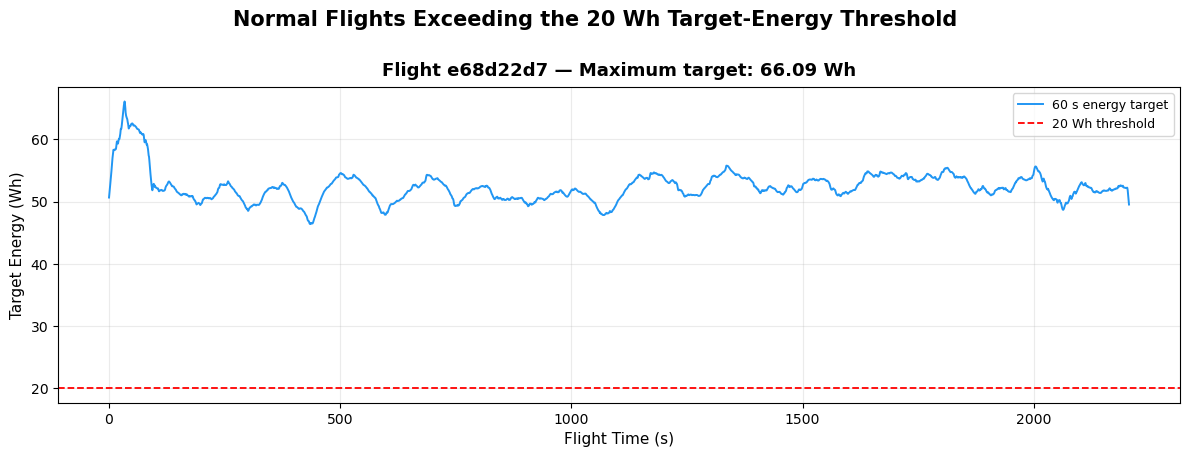

In [220]:
suspect_flights = flight_summary["log_id"].tolist()
n_plots = min(4, len(suspect_flights))

fig, axes = plt.subplots(
    n_plots, 1,
    figsize=(12, 4.5 * n_plots),
    sharex=False
)

if n_plots == 1:
    axes = [axes]

for ax, fid in zip(axes, suspect_flights[:4]):
    fd = (
        normal_df[normal_df["log_id"] == fid]
        .sort_values("time_s")
    )

    ax.plot(
        fd["time_s"],
        fd[target_col],
        linewidth=1.4,
        color="#2196F3",
        label="60 s energy target"
    )

    ax.axhline(
        THRESHOLD,
        color="red",
        linestyle="--",
        linewidth=1.3,
        label=f"20 Wh threshold"
    )

    ax.set_title(
        f"Flight {fid[:8]} — Maximum target: {fd[target_col].max():.2f} Wh",
        fontsize=13,
        fontweight="bold",
        pad=8
    )

    ax.set_xlabel(
        "Flight Time (s)",
        fontsize=11
    )

    ax.set_ylabel(
        "Target Energy (Wh)",
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.legend(
        fontsize=9,
        loc="upper right",
        frameon=True
    )

    ax.grid(
        True,
        alpha=0.25
    )

fig.suptitle(
    "Normal Flights Exceeding the 20 Wh Target-Energy Threshold",
    fontsize=15,
    fontweight="bold",
    y=1.005
)

plt.tight_layout()

plt.savefig(
    EDA_DIR / "outlier_timeseries_suspect_flights.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. IQR and Z-score statistical confirmation

IQR Method
  Q1=0.2779  Q3=3.0706  IQR=2.7926
  Outlier upper bound (Q3+3×IQR): 11.4485 Wh
  Rows above threshold: 22,062

Z-score Method (|z| > 3)
  Rows flagged: 22,062

Percentile Breakdown
  p90: 3.6068 Wh
  p95: 5.3111 Wh
  p99: 53.0762 Wh
  p99.5: 54.0081 Wh
  p99.9: 58.3473 Wh
  p100: 66.0877 Wh


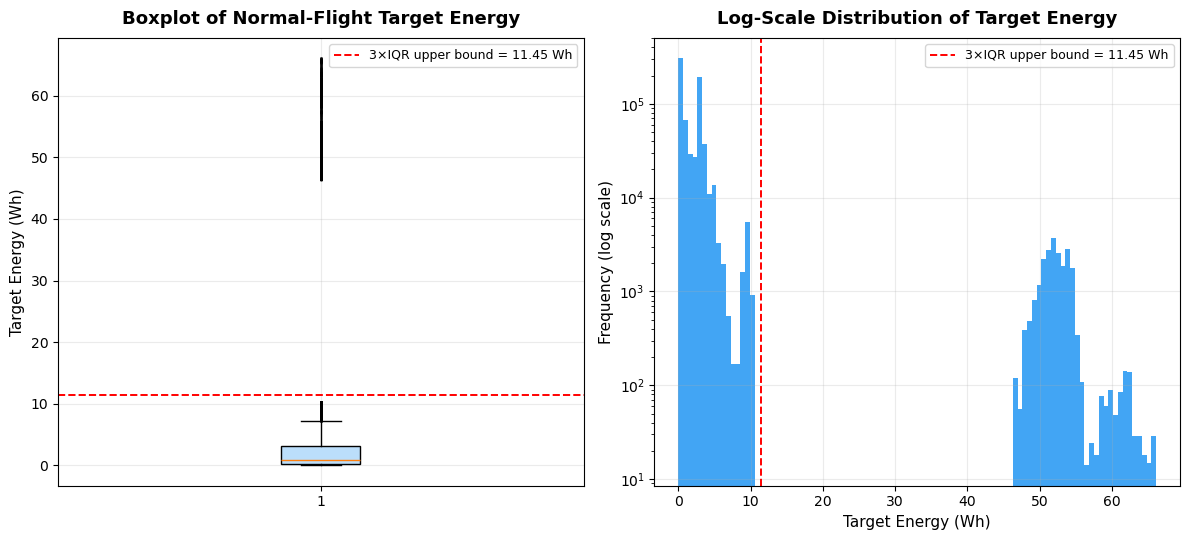

In [221]:
target_vals = normal_df[target_col].dropna()

Q1 = target_vals.quantile(0.25)
Q3 = target_vals.quantile(0.75)
IQR = Q3 - Q1
iqr_upper = Q3 + 3 * IQR

z_scores = np.abs(stats.zscore(target_vals))

print("IQR Method")
print(f"  Q1={Q1:.4f}  Q3={Q3:.4f}  IQR={IQR:.4f}")
print(f"  Outlier upper bound (Q3+3×IQR): {iqr_upper:.4f} Wh")
print(f"  Rows above threshold: {(target_vals > iqr_upper).sum():,}")

print("\nZ-score Method (|z| > 3)")
print(f"  Rows flagged: {(z_scores > 3).sum():,}")

print("\nPercentile Breakdown")
for p in [90, 95, 99, 99.5, 99.9, 100]:
    print(f"  p{p}: {np.percentile(target_vals, p):.4f} Wh")


# Create thesis-ready figure
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 5.5)
)

# Boxplot
ax1.boxplot(
    target_vals,
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="#BBDEFB"),
    flierprops=dict(marker=".", markersize=2, alpha=0.35)
)

ax1.axhline(
    iqr_upper,
    color="red",
    linestyle="--",
    linewidth=1.4,
    label=f"3×IQR upper bound = {iqr_upper:.2f} Wh"
)

ax1.set_title(
    "Boxplot of Normal-Flight Target Energy",
    fontsize=13,
    fontweight="bold",
    pad=10
)

ax1.set_ylabel(
    "Target Energy (Wh)",
    fontsize=11
)

ax1.tick_params(
    axis="both",
    labelsize=10
)

ax1.legend(
    fontsize=9,
    loc="upper right"
)

ax1.grid(
    True,
    alpha=0.25
)


# Log-scale histogram
ax2.hist(
    target_vals,
    bins=100,
    color="#2196F3",
    alpha=0.85,
    edgecolor="none",
    log=True
)

ax2.axvline(
    iqr_upper,
    color="red",
    linestyle="--",
    linewidth=1.4,
    label=f"3×IQR upper bound = {iqr_upper:.2f} Wh"
)

ax2.set_title(
    "Log-Scale Distribution of Target Energy",
    fontsize=13,
    fontweight="bold",
    pad=10
)

ax2.set_xlabel(
    "Target Energy (Wh)",
    fontsize=11
)

ax2.set_ylabel(
    "Frequency (log scale)",
    fontsize=11
)

ax2.tick_params(
    axis="both",
    labelsize=10
)

ax2.legend(
    fontsize=9,
    loc="upper right"
)

ax2.grid(
    True,
    alpha=0.25
)


plt.tight_layout()

plt.savefig(
    EDA_DIR / "outlier_iqr_zscore_test.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Power vs target scatter (confirm it's a different aircraft)

Top 20 high-target rows:
                              log_id  time_s   power_w  energy_increment_wh  cumulative_energy_wh  target_energy_next_60s_wh
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.6 3593.2422             0.099812             23.708082                  66.087665
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.7 3593.2422             0.099812             23.807894                  66.071539
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.8 3387.1223             0.094087             23.901981                  66.061138
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.5 3226.6917             0.089630             23.608269                  66.060095
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.9 3387.1223             0.094087             23.996067                  66.026597
e68d22d7-7b96-4767-a074-edfca1c7f78c    33.4 3226.6917             0.089630             23.518639                  66.022343
e68d22d7-7b96-4767-a074-edfca1c7f78c    34.0 3477.0989             0.096586             24.092653   

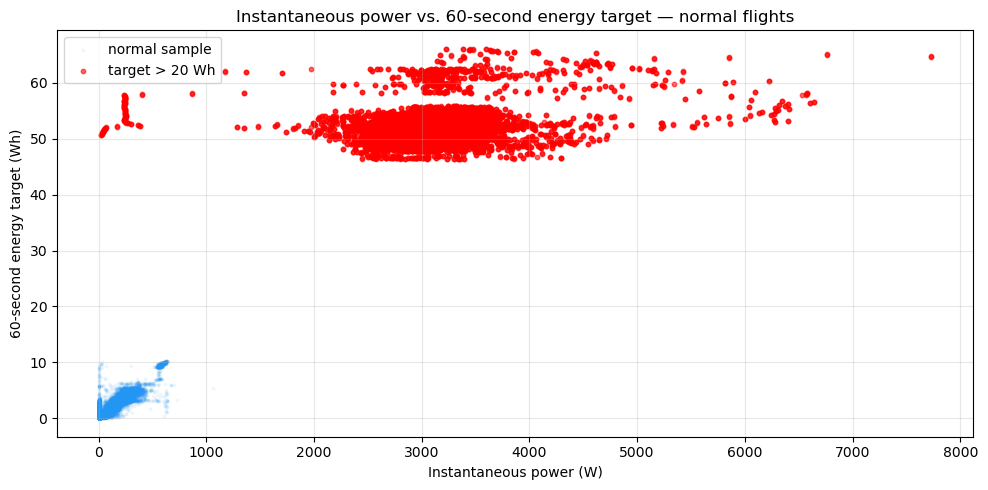

In [222]:
high_rows = normal_df[normal_df[target_col] > THRESHOLD][
    ["log_id", "time_s", "power_w", "energy_increment_wh",
     "cumulative_energy_wh", target_col]
].sort_values(target_col, ascending=False)

print("Top 20 high-target rows:")
print(high_rows.head(20).to_string(index=False))
print(f"\n  mean power_w (outlier rows)  : {high_rows['power_w'].mean():.2f} W")
print(f"  max  power_w (outlier rows)  : {high_rows['power_w'].max():.2f} W")
print(f"  Normal fleet mean power_w    : {normal_df['power_w'].mean():.2f} W")
print(f"  Normal fleet p99 power_w     : {normal_df['power_w'].quantile(0.99):.2f} W")

fig, ax = plt.subplots(figsize=(10, 5))
sample = normal_df.sample(min(50000, len(normal_df)), random_state=42)
ax.scatter(sample["power_w"], sample[target_col],
           alpha=0.05, s=3, color="#2196F3", label="normal sample")
ax.scatter(high_rows["power_w"], high_rows[target_col],
           alpha=0.6, s=10, color="red", label=f"target > {THRESHOLD} Wh")
ax.set_xlabel("Instantaneous power (W)")
ax.set_ylabel("60-second energy target (Wh)")
ax.set_title("Instantaneous power vs. 60-second energy target — normal flights")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "outlier_power_vs_target.png", dpi=150)
plt.show()

## 8. Remove outlier flight and update both df and normal_df

In [223]:
before_shape   = df.shape
before_flights = df["log_id"].nunique()

suspect_flights = flight_summary["log_id"].dropna().unique().tolist()
df        = df[~df["log_id"].isin(suspect_flights)].copy()
normal_df = df[df["dataset_label"] == "normal"].copy()  # refresh after removal

print("Before:", before_shape)
print("After :", df.shape)
print("Flights removed:", before_flights - df["log_id"].nunique())
print("Suspect flights:", suspect_flights)

Before: (1019991, 378)
After : (997929, 378)
Flights removed: 1
Suspect flights: ['e68d22d7-7b96-4767-a074-edfca1c7f78c']


## 9. Temporal gap check

In [224]:
expected_gap = 0.1
allowed_gap  = 0.15

df_sorted          = df.sort_values(["log_id", "time_s"]).copy()
df_sorted["time_gap"] = df_sorted.groupby("log_id")["time_s"].diff()
time_gaps          = df_sorted["time_gap"].dropna()

gap_summary = pd.DataFrame({
    "Check": [
        "Expected gap for 10 Hz data",
        "Average observed gap",
        "Median observed gap",
        "Smallest observed gap",
        "Largest observed gap",
        "Total time gaps checked",
        "Number of gaps above allowed limit",
        "Percentage of large gaps"
    ],
    "Result": [
        expected_gap,
        round(time_gaps.mean(), 6),
        round(time_gaps.median(), 6),
        round(time_gaps.min(), 6),
        round(time_gaps.max(), 6),
        len(time_gaps),
        (time_gaps > allowed_gap).sum(),
        round((time_gaps > allowed_gap).mean() * 100, 4)
    ]
})
display(gap_summary)

,Check,Result
0,Expected gap for 10 Hz data,0.100000
1,Average observed gap,0.100245
2,Median observed gap,0.100000
3,Smallest observed gap,0.100000
4,Largest observed gap,6.700000
5,Total time gaps checked,997758.000000
6,Number of gaps above allowed limit,411.000000
7,Percentage of large gaps,0.041200


## 10. Gap review by flight

In [225]:
gap_rows = df_sorted[df_sorted["time_gap"] > allowed_gap].copy()

gap_summary_by_flight = (
    gap_rows.groupby("log_id")
    .agg(
        number_of_gaps=("time_gap", "count"),
        max_gap_s=("time_gap", "max"),
        mean_gap_s=("time_gap", "mean"),
        first_gap_time_s=("time_s", "min"),
        last_gap_time_s=("time_s", "max")
    )
    .reset_index()
    .sort_values("max_gap_s", ascending=False)
)

display(gap_summary_by_flight.head(20))
print("Total flights with gaps:", gap_summary_by_flight["log_id"].nunique())
print("Total gap rows:", len(gap_rows))

,log_id,number_of_gaps,max_gap_s,mean_gap_s,first_gap_time_s,last_gap_time_s
36,5c1b7f3d-57d4-427e-b302-d22956f66f0b,1,6.7,6.700000,7.9,7.9
3,0332fefb-a16f-4ff9-b626-e8a158346ff4,30,2.5,0.980000,167.0,347.3
19,1b9a2fee-db24-4c6d-b88d-ac3950286eae,6,2.0,1.000000,33.7,317.8
7,06b760bf-d457-46b7-84e1-f08c180aefb3,1,2.0,2.000000,561.6,561.6
43,75678c0f-b911-4875-a2cf-bc317c489c22,8,2.0,1.000000,59.3,779.9
49,80bfac4b-fa67-4fc7-8833-7789229fb78f,6,1.5,1.000000,78.3,284.6
4,03a4237b-52e2-4327-8bfd-0f6e4d6de940,6,1.5,1.250000,29.0,308.2
37,66c5f92a-1fd2-4ddb-b9d8-aba8e1dfcacb,15,1.5,0.800000,27.1,776.4
8,08aab983-e7b7-41b0-a3fe-c719f68cc230,8,1.5,0.850000,1023.6,1089.1
30,4259190b-f88c-4416-b276-dd04d854e70f,4,1.5,0.850000,6.3,238.3


Total flights with gaps: 84
Total gap rows: 411


## 11. Remove flights with serious gaps

In [226]:
SERIOUS_GAP_THRESHOLD = 2.0

serious_gap_flights = gap_summary_by_flight[
    gap_summary_by_flight["max_gap_s"] > SERIOUS_GAP_THRESHOLD
]["log_id"].tolist()

print("Flights with serious gaps:", len(serious_gap_flights))
print(serious_gap_flights)

before_rows    = len(df)
before_flights = df["log_id"].nunique()

df = df[~df["log_id"].isin(serious_gap_flights)].copy()

print(f"Rows removed    : {before_rows - len(df):,}")
print(f"Flights removed : {before_flights - df['log_id'].nunique()}")
print(f"Remaining rows  : {len(df):,}")
print(f"Remaining flights: {df['log_id'].nunique()}")

Flights with serious gaps: 3
['5c1b7f3d-57d4-427e-b302-d22956f66f0b', '0332fefb-a16f-4ff9-b626-e8a158346ff4', '1b9a2fee-db24-4c6d-b88d-ac3950286eae']
Rows removed    : 26,107
Flights removed : 3
Remaining rows  : 971,822
Remaining flights: 168


In [227]:
# Analyse remaining minor gaps (0.15s - 2.0s)
gap_analysis = []

for lid, grp in df.sort_values(["log_id","time_s"]).groupby("log_id"):
    grp = grp.sort_values("time_s").reset_index(drop=True)
    gaps = grp["time_s"].diff()
    bad_gaps = gaps[(gaps > 0.15) & (gaps <= 2.0)]
    if len(bad_gaps) > 0:
        gap_analysis.append({
            "log_id":        lid,
            "dataset_label": grp["dataset_label"].iloc[0],
            "n_gaps":        len(bad_gaps),
            "max_gap_s":     bad_gaps.max(),
            "total_rows":    len(grp),
            "gap_rows_%":    round(len(bad_gaps)/len(grp)*100, 2),
        })

gap_df = pd.DataFrame(gap_analysis).sort_values("max_gap_s", ascending=False)
print(f"Flights with minor gaps (0.15-2.0s): {len(gap_df)}")
print(f"Total gap instances: {gap_df['n_gaps'].sum()}")
print(f"\n=== Per flight ===")
print(gap_df[["log_id","dataset_label","n_gaps","max_gap_s","gap_rows_%","total_rows"]].to_string(index=False))

Flights with minor gaps (0.15-2.0s): 81
Total gap instances: 374

=== Per flight ===
                              log_id dataset_label  n_gaps  max_gap_s  gap_rows_%  total_rows
75678c0f-b911-4875-a2cf-bc317c489c22      abnormal       8        2.0        0.08       10207
06b760bf-d457-46b7-84e1-f08c180aefb3      abnormal       1        2.0        0.02        5848
66c5f92a-1fd2-4ddb-b9d8-aba8e1dfcacb        normal      15        1.5        0.19        7900
80bfac4b-fa67-4fc7-8833-7789229fb78f      abnormal       6        1.5        0.21        2850
3d552044-12aa-4b10-919d-2bdfa037425a      abnormal       5        1.5        0.03       18163
08aab983-e7b7-41b0-a3fe-c719f68cc230      abnormal       8        1.5        0.07       11673
4259190b-f88c-4416-b276-dd04d854e70f        normal       4        1.5        0.15        2718
03a4237b-52e2-4327-8bfd-0f6e4d6de940        normal       6        1.5        0.18        3275
f2ffd430-5ef3-4de2-b60e-b47d6cf044b2      abnormal       4        1.4

In [228]:
# Flag rows immediately after a gap > 0.15s
df = df.sort_values(["log_id","time_s"]).reset_index(drop=True)

df["time_gap"] = df.groupby("log_id")["time_s"].diff().fillna(0)
df["post_gap_flag"] = (df["time_gap"] > 0.15).astype(int)

print(f"Rows flagged as post-gap: {df['post_gap_flag'].sum():,}")
print(f"As % of total rows: {df['post_gap_flag'].mean()*100:.3f}%")

Rows flagged as post-gap: 374
As % of total rows: 0.038%


In [229]:
print("=== battery_status__scale analysis ===")
print(f"Unique values: {df['battery_status__scale'].nunique()}")
print(f"Min: {df['battery_status__scale'].min():.6f}")
print(f"Max: {df['battery_status__scale'].max():.6f}")
print(f"Mean: {df['battery_status__scale'].mean():.6f}")
print(f"Rows exactly 1.0: {(df['battery_status__scale']==1.0).sum():,}")
print(f"Rows > 1.0: {(df['battery_status__scale']>1.0).sum():,}")
print(f"Rows < 1.0: {(df['battery_status__scale']<1.0).sum():,}")

print("\n=== Per flight — does scale vary within flight? ===")
scale_var = df.groupby("log_id")["battery_status__scale"].agg(["min","max","nunique","mean"])
scale_var["varies"] = scale_var["nunique"] > 1
print(f"Flights where scale is constant : {(~scale_var['varies']).sum()}")
print(f"Flights where scale varies      : {scale_var['varies'].sum()}")
print(f"\nFlights with scale != 1.0:")
print(scale_var[scale_var["min"] != 1.0][["min","max","nunique","mean"]].head(10).to_string())

=== battery_status__scale analysis ===
Unique values: 164359
Min: 1.000000
Max: 1.237842
Mean: 1.055164
Rows exactly 1.0: 168,169
Rows > 1.0: 803,653
Rows < 1.0: 0

=== Per flight — does scale vary within flight? ===
Flights where scale is constant : 6
Flights where scale varies      : 162

Flights with scale != 1.0:
                                           min       max  nunique      mean
log_id                                                                     
00209ad8-f7c4-4d6f-839c-af19d8203e9b  1.031092  1.113530     1389  1.084995
022107fb-9d00-47b7-bc42-ea336f7040f3  1.070757  1.141592      704  1.116663
03a4237b-52e2-4327-8bfd-0f6e4d6de940  1.035711  1.147764      652  1.089183
0b7bf455-91a5-497b-ae0f-c021491c15fc  1.078571  1.173672     1012  1.125540
0baaaf4d-45a3-4dde-bd08-d8a8f13418cd  1.017437  1.125752      819  1.072769
0e1b8623-6cc4-4b3e-a709-577a07e976a0  1.000893  1.089217     1122  1.044329
106c4ba7-98be-4b9a-b901-ea73e16e82cf  1.043643  1.153780      817  1.1000

In [230]:
print("=== battery_status__remaining by label ===")
for lbl in ["normal","abnormal"]:
    sub = df[df["dataset_label"]==lbl]["battery_status__remaining"]
    print(f"{lbl}: mean={sub.mean():.3f}  std={sub.std():.3f}  "
          f"min={sub.min():.3f}  max={sub.max():.3f}")

print("\n=== Correlation with target per label ===")
for lbl in ["normal","abnormal"]:
    sub = df[df["dataset_label"]==lbl]
    corr = sub["battery_status__remaining"].corr(sub["target_energy_next_60s_wh"])
    print(f"{lbl}: corr={corr:.4f}")

print("\n=== Does remaining decrease monotonically within flights? ===")
non_mono = 0
for lid, grp in df.sort_values(["log_id","time_s"]).groupby("log_id"):
    rem = grp["battery_status__remaining"].values
    if not all(rem[i] >= rem[i+1] for i in range(len(rem)-1)):
        non_mono += 1
print(f"Flights where remaining is NOT monotonically decreasing: {non_mono}")

=== battery_status__remaining by label ===
normal: mean=0.705  std=0.230  min=0.036  max=1.000
abnormal: mean=0.684  std=0.230  min=0.042  max=1.000

=== Correlation with target per label ===
normal: corr=-0.2081
abnormal: corr=0.0770

=== Does remaining decrease monotonically within flights? ===
Flights where remaining is NOT monotonically decreasing: 158


## 12. Verify gaps are gone

In [231]:

df_sorted          = df.sort_values(["log_id", "time_s"]).copy()
df_sorted["time_gap"] = df_sorted.groupby("log_id")["time_s"].diff()
time_gaps_clean    = df_sorted["time_gap"].dropna()

print("Post-removal gap check:")
print(time_gaps_clean.describe().round(6))
print(f"Gaps > 0.15s : {(time_gaps_clean > 0.15).sum()}")
print(f"Gaps > 2.0s  : {(time_gaps_clean > 2.0).sum()}")

Post-removal gap check:
count    971654.000000
mean          0.100212
std           0.012461
min           0.100000
25%           0.100000
50%           0.100000
75%           0.100000
max           2.000000
Name: time_gap, dtype: float64
Gaps > 0.15s : 374
Gaps > 2.0s  : 0


## 13. Class imbalance chart

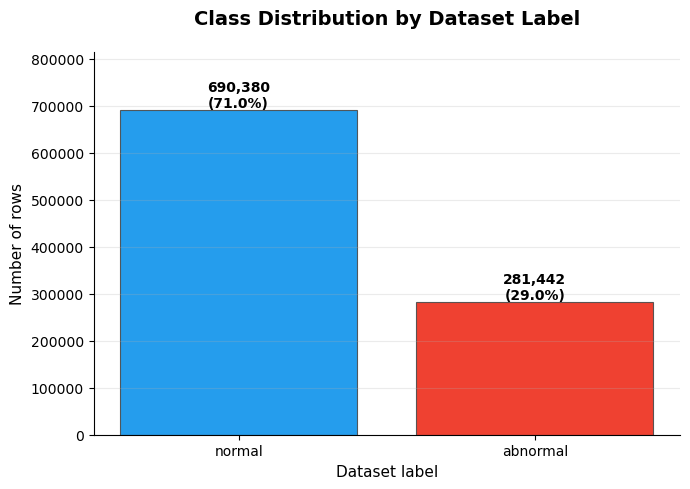

dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


In [232]:
label_counts = df["dataset_label"].value_counts()
total_rows   = label_counts.sum()
percentages  = (label_counts / total_rows) * 100

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(label_counts.index, label_counts.values,
              color=["#0D93EC", "#EE2C1A"],
              edgecolor="#4A4A4A", linewidth=0.8, alpha=0.9)

for bar, count, pct in zip(bars, label_counts.values, percentages.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{count:,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.set_title("Class Distribution by Dataset Label", fontsize=14,
             fontweight="bold", pad=20)
ax.set_xlabel("Dataset label", fontsize=11)
ax.set_ylabel("Number of rows", fontsize=11)
ax.set_ylim(0, label_counts.max() * 1.18)
ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig(EDA_DIR / "class_distribution.png", dpi=150)
plt.show()
print(label_counts)

## 14. Target distribution analysis

count    971822.0000
mean          2.3704
std           3.5056
min           0.0000
25%           0.2612
50%           1.4785
75%           3.1489
max          27.5020
Name: target_energy_next_60s_wh, dtype: float64

Skewness : 3.8799
Kurtosis : 19.1032


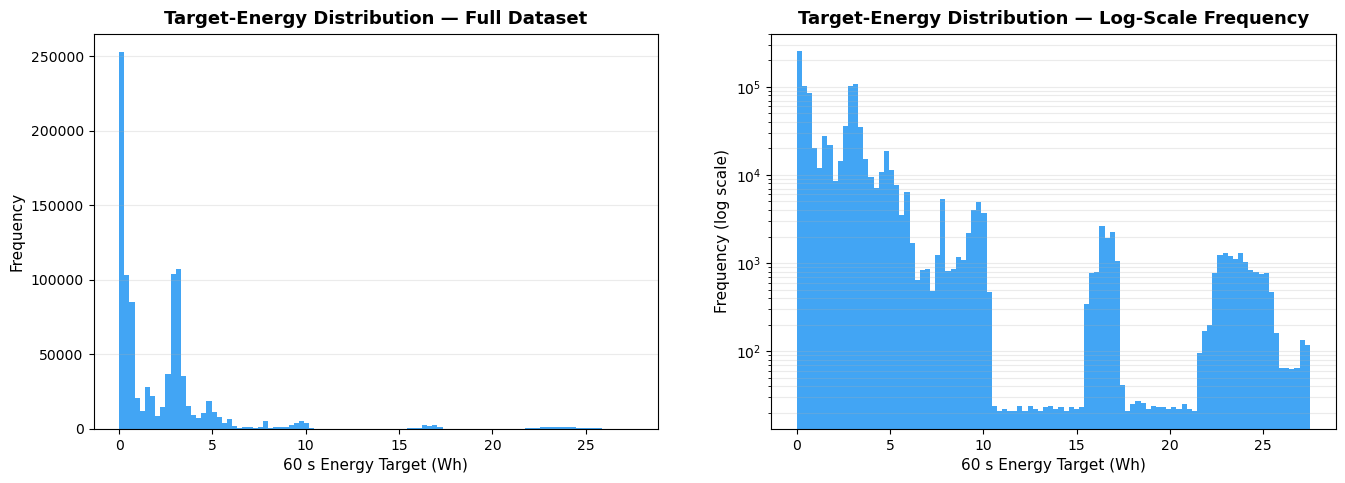

In [233]:
# ============================================================
# FIGURE 4.2 — Target distribution: full dataset
# ============================================================

print(df[target_col].describe().round(4))
print(f"\nSkewness : {df[target_col].skew():.4f}")
print(f"Kurtosis : {df[target_col].kurt():.4f}")

target_values = df[target_col].dropna()

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.5, 5.2)
)

# ------------------------------------------------------------
# Left — standard frequency scale
# ------------------------------------------------------------

axes[0].hist(
    target_values,
    bins=100,
    color="#2196F3",
    alpha=0.85,
    edgecolor="none"
)

axes[0].set_title(
    "Target-Energy Distribution — Full Dataset",
    fontsize=13,
    fontweight="bold",
    pad=7
)

axes[0].set_xlabel(
    "60 s Energy Target (Wh)",
    fontsize=11
)

axes[0].set_ylabel(
    "Frequency",
    fontsize=11
)

axes[0].tick_params(
    axis="both",
    labelsize=10
)

axes[0].grid(
    True,
    alpha=0.25,
    axis="y"
)


# ------------------------------------------------------------
# Right — logarithmic frequency scale
# ------------------------------------------------------------

axes[1].hist(
    target_values,
    bins=100,
    color="#2196F3",
    alpha=0.85,
    edgecolor="none",
    log=True
)

axes[1].set_title(
    "Target-Energy Distribution — Log-Scale Frequency",
    fontsize=13,
    fontweight="bold",
    pad=7
)

axes[1].set_xlabel(
    "60 s Energy Target (Wh)",
    fontsize=11
)

axes[1].set_ylabel(
    "Frequency (log scale)",
    fontsize=11
)

axes[1].tick_params(
    axis="both",
    labelsize=10
)

axes[1].grid(
    True,
    alpha=0.25,
    axis="y",
    which="both"
)


fig.subplots_adjust(
    left=0.07,
    right=0.99,
    bottom=0.14,
    top=0.90,
    wspace=0.20
)

plt.savefig(
    EDA_DIR / "target_distribution_thesis.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close()

## 15. Target distribution: normal vs abnormal (3-panel)

normal: n=690,380  median=0.786  p99=9.225  max=10.309
abnormal: n=281,442  median=2.638  p99=24.689  max=27.502


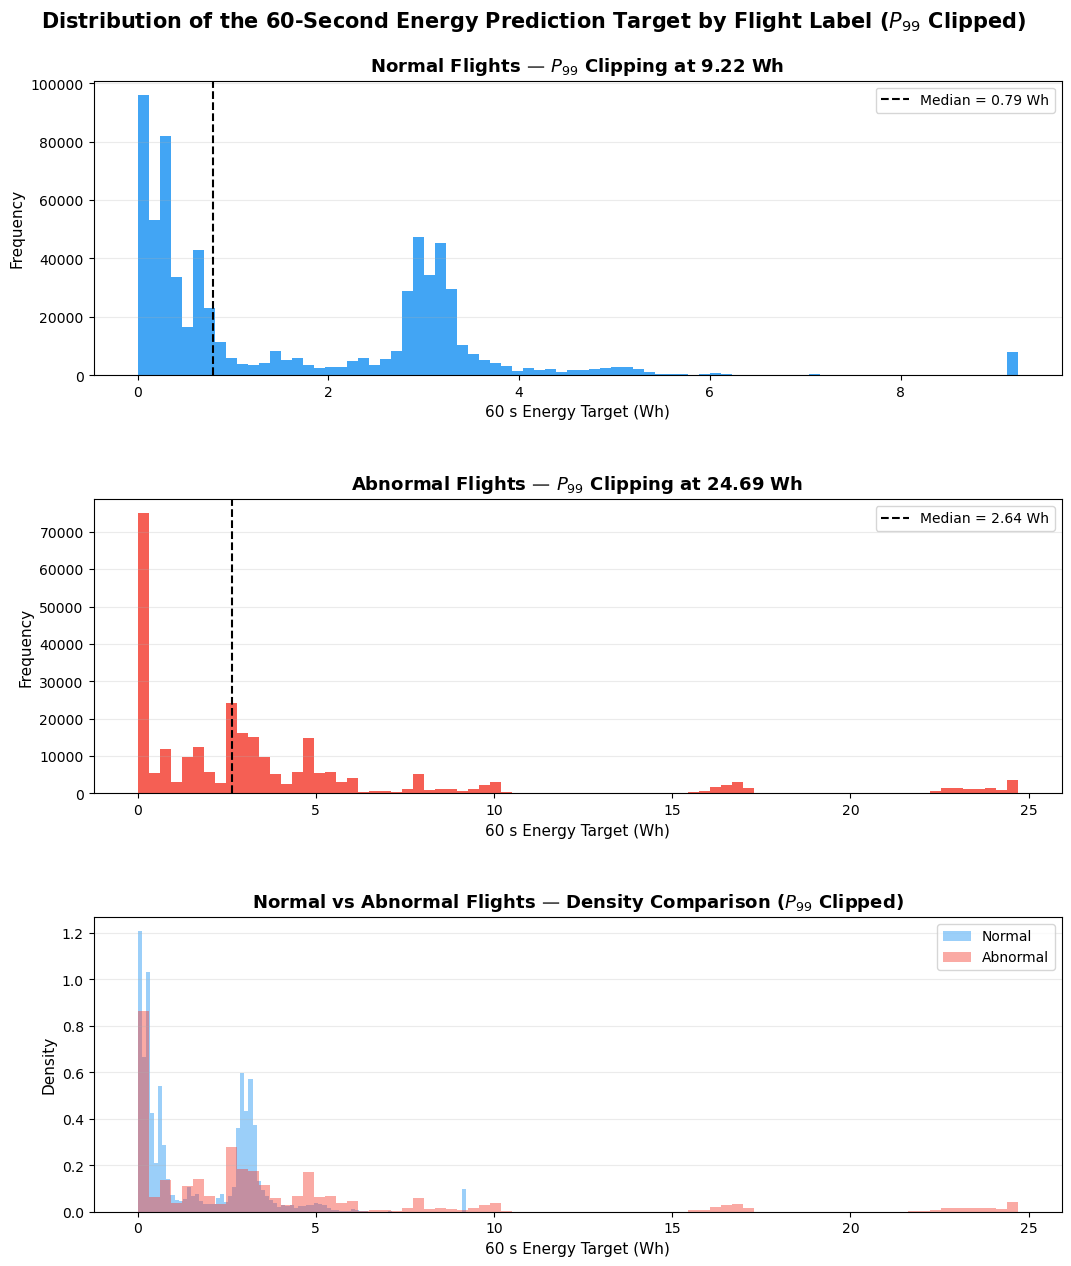

In [234]:
# ============================================================
# FIGURE 4.3 — Target distribution by flight label
# Stacked vertically for thesis readability
# ============================================================

colors = {
    "normal": "#2196F3",
    "abnormal": "#F44336"
}

fig, axes = plt.subplots(
    3, 1,
    figsize=(11, 13)
)

# ------------------------------------------------------------
# Normal and abnormal distributions
# ------------------------------------------------------------

for ax, label in zip(
    axes[:2],
    ["normal", "abnormal"]
):
    subset = (
        df.loc[
            df["dataset_label"] == label,
            target_col
        ]
        .dropna()
    )

    p99 = np.percentile(subset, 99)
    median = subset.median()
    clipped = subset.clip(upper=p99)

    print(
        f"{label}: "
        f"n={len(subset):,}  "
        f"median={median:.3f}  "
        f"p99={p99:.3f}  "
        f"max={subset.max():.3f}"
    )

    ax.hist(
        clipped,
        bins=80,
        color=colors[label],
        alpha=0.85,
        edgecolor="none"
    )

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Median = {median:.2f} Wh"
    )

    ax.set_title(
        f"{label.capitalize()} Flights — "
        f"$P_{{99}}$ Clipping at {p99:.2f} Wh",
        fontsize=13,
        fontweight="bold",
        pad=7
    )

    ax.set_xlabel(
        "60 s Energy Target (Wh)",
        fontsize=11
    )

    ax.set_ylabel(
        "Frequency",
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.legend(
        fontsize=10,
        loc="upper right",
        frameon=True
    )

    ax.grid(
        True,
        alpha=0.25,
        axis="y"
    )


# ------------------------------------------------------------
# Overlay — normal vs abnormal density
# ------------------------------------------------------------

ax = axes[2]

for label in ["normal", "abnormal"]:

    subset = (
        df.loc[
            df["dataset_label"] == label,
            target_col
        ]
        .dropna()
    )

    p99 = np.percentile(subset, 99)
    clipped = subset.clip(upper=p99)

    ax.hist(
        clipped,
        bins=80,
        alpha=0.45,
        label=label.capitalize(),
        color=colors[label],
        edgecolor="none",
        density=True
    )

    ax.set_title(
        r"Normal vs Abnormal Flights — Density Comparison ($P_{99}$ Clipped)",
        fontsize=13,
        fontweight="bold",
        pad=7
    )

ax.set_xlabel(
    "60 s Energy Target (Wh)",
    fontsize=11
)

ax.set_ylabel(
    "Density",
    fontsize=11
)

ax.tick_params(
    axis="both",
    labelsize=10
)

ax.legend(
    fontsize=10,
    loc="upper right",
    frameon=True
)

ax.grid(
    True,
    alpha=0.25,
    axis="y"
)


# ------------------------------------------------------------
# Overall title and compact vertical layout
# ------------------------------------------------------------

fig.suptitle(
    r"Distribution of the 60-Second Energy Prediction Target by Flight Label ($P_{99}$ Clipped)",
    fontsize=15,
    fontweight="bold",
    y=0.985
)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.06,
    top=0.93,
    hspace=0.42
)

plt.savefig(
    EDA_DIR / "target_distribution_by_label_thesis.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close()

## 16. Normal vs Abnormal feature distributions

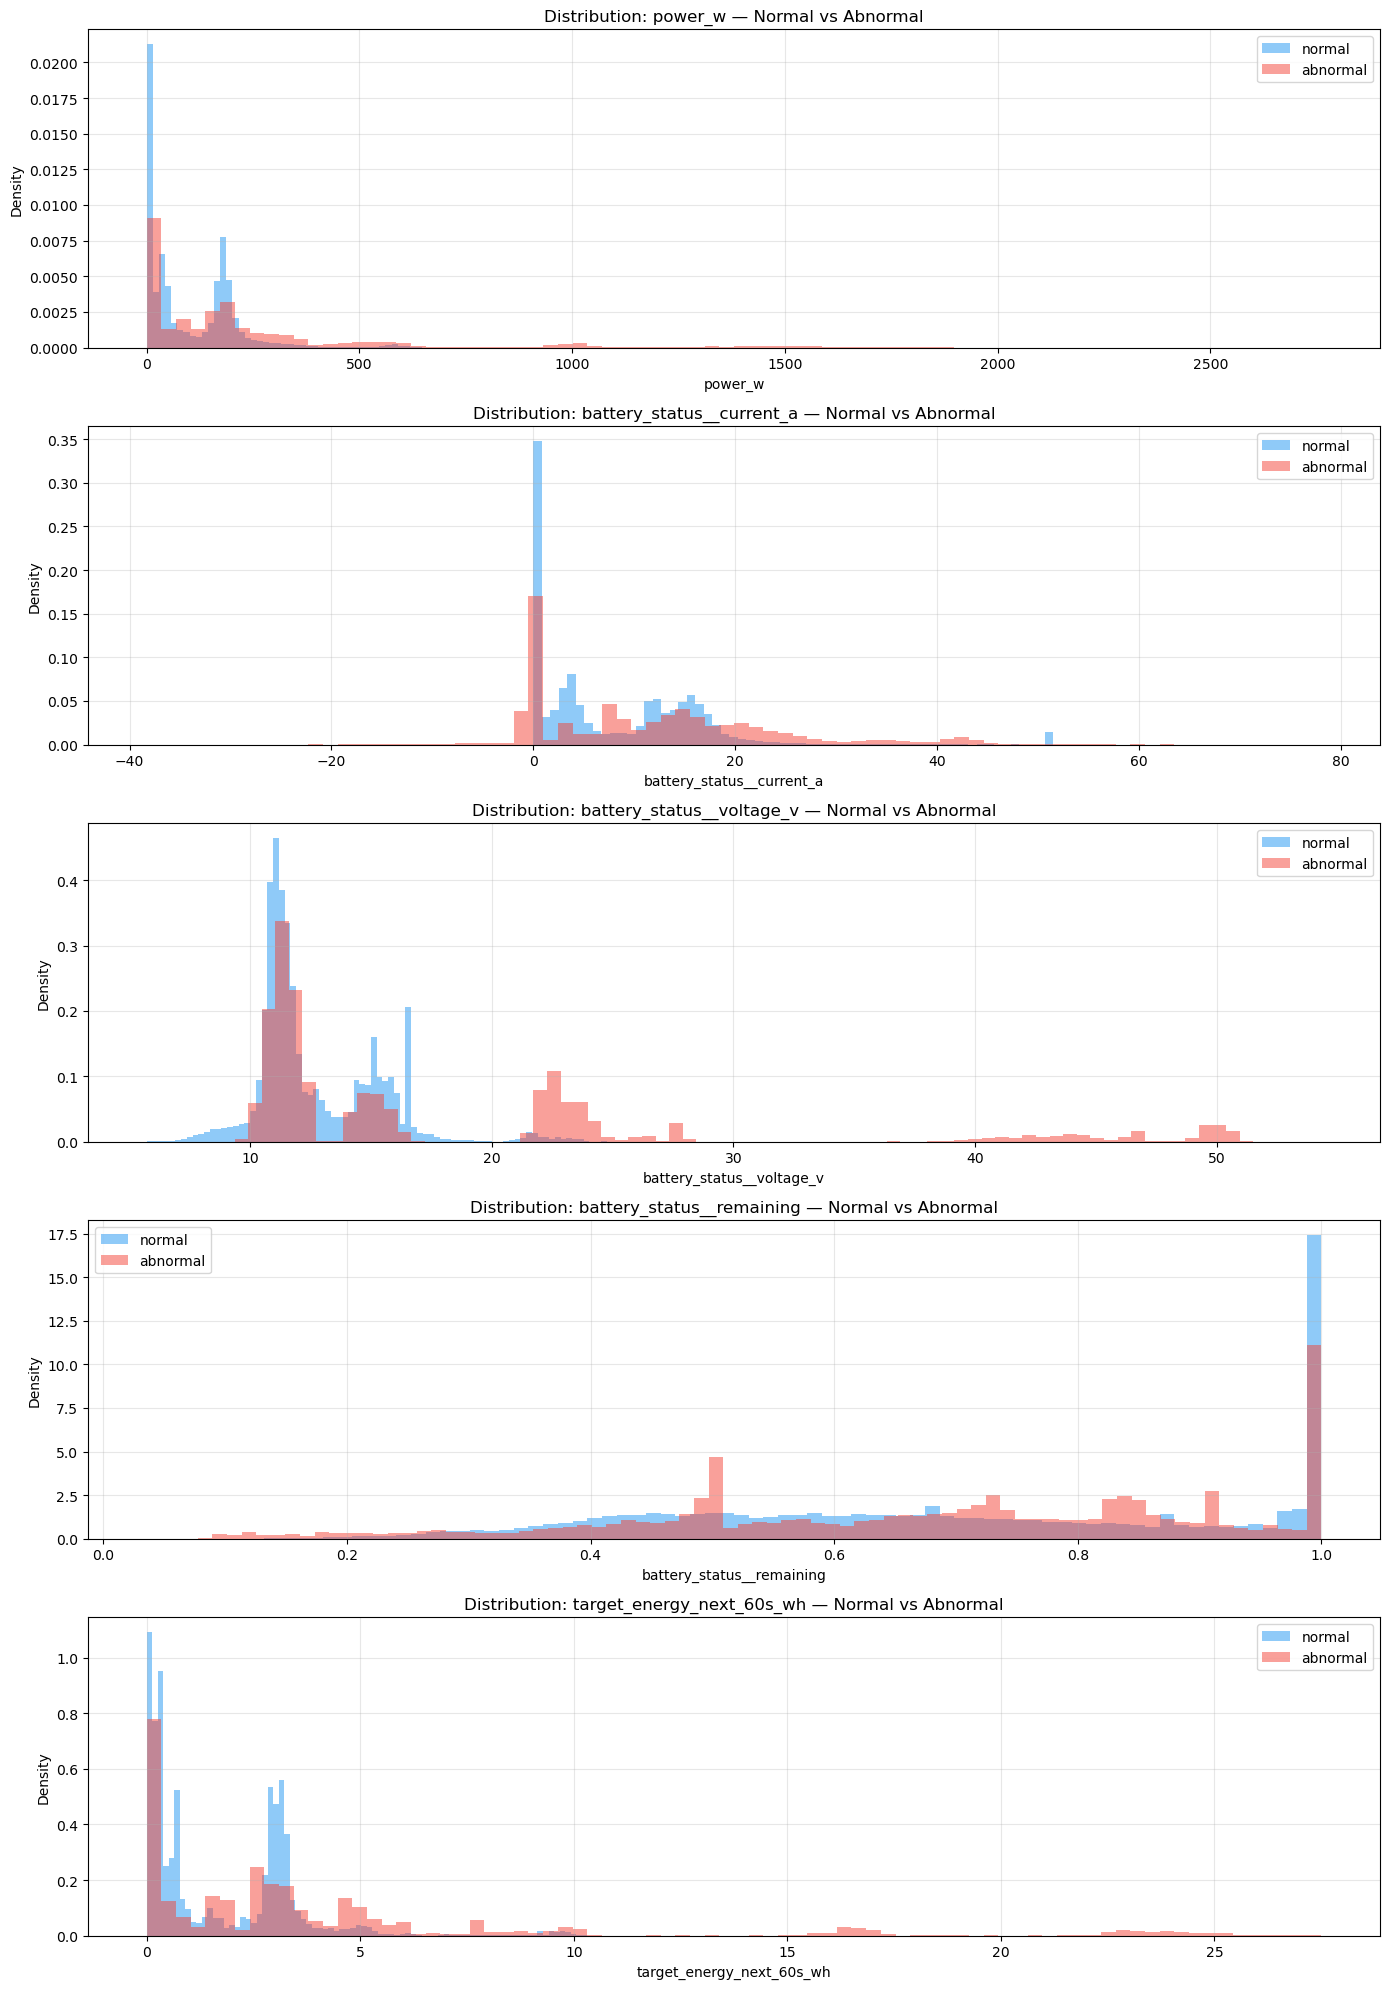


Median values — Normal vs Abnormal:
dataset_label              abnormal   normal
power_w                    150.9856  51.7438
battery_status__current_a    9.2087   4.6624
battery_status__voltage_v   12.3888  11.6405
battery_status__remaining    0.7111   0.6915
target_energy_next_60s_wh    2.6381   0.7862


In [235]:
compare_features = [
    "power_w", "battery_status__current_a",
    "battery_status__voltage_v",
    "battery_status__remaining", target_col
]
compare_features = [f for f in compare_features if f in df.columns]

fig, axes = plt.subplots(len(compare_features), 1,
                          figsize=(14, 4 * len(compare_features)))

for ax, feat in zip(axes, compare_features):
    for label, color in [("normal", "#2196F3"), ("abnormal", "#F44336")]:
        vals = df[df["dataset_label"] == label][feat].dropna()
        ax.hist(vals, bins=80, alpha=0.5, color=color,
                label=label, edgecolor="none", density=True)
    ax.set_title(f"Distribution: {feat} — Normal vs Abnormal")
    ax.set_xlabel(feat)
    ax.set_ylabel("Density")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(EDA_DIR / "normal_vs_abnormal_feature_distributions.png", dpi=150)
plt.show()

print("\nMedian values — Normal vs Abnormal:")
print(df.groupby("dataset_label")[compare_features].median().round(4).T.to_string())

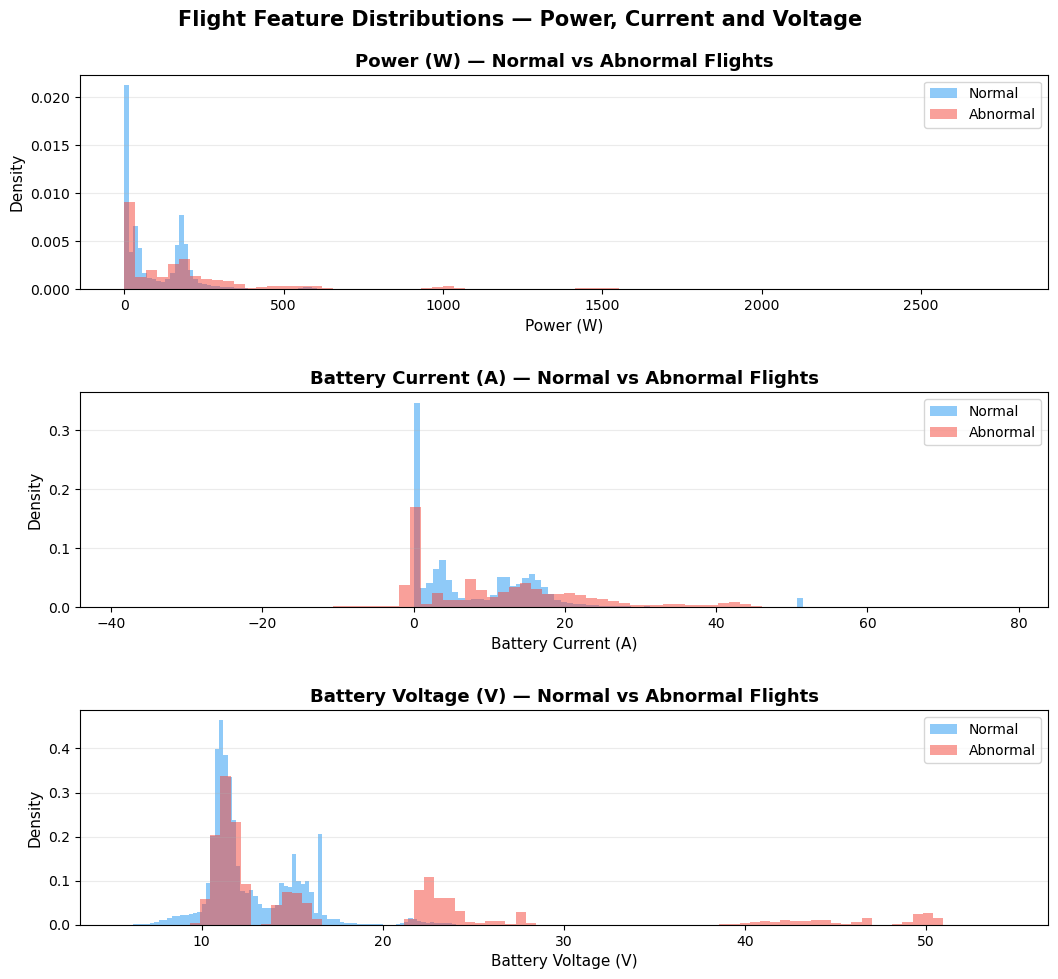

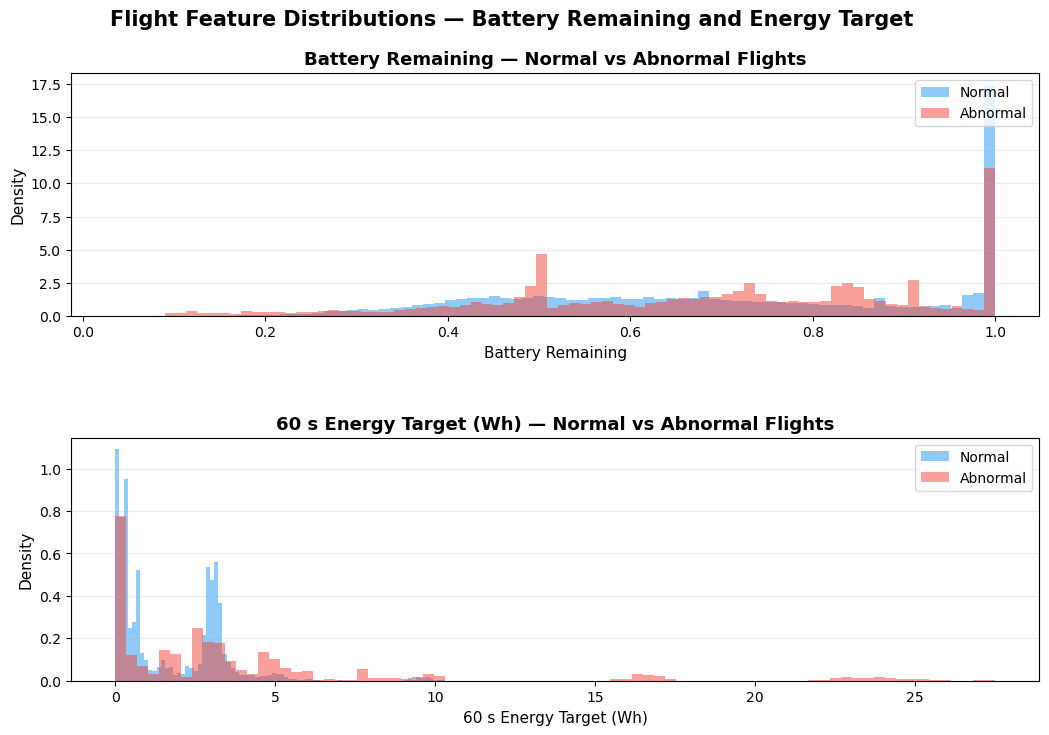


Median values — Normal vs Abnormal:
dataset_label              abnormal   normal
power_w                    150.9856  51.7438
battery_status__current_a    9.2087   4.6624
battery_status__voltage_v   12.3888  11.6405
battery_status__remaining    0.7111   0.6915
target_energy_next_60s_wh    2.6381   0.7862


In [236]:
# ============================================================
# FIGURE 4.4 — Feature distributions: Normal vs Abnormal
# Split into two thesis-readable figures
# ============================================================

compare_features = [
    "power_w",
    "battery_status__current_a",
    "battery_status__voltage_v",
    "battery_status__remaining",
    target_col
]

compare_features = [
    f for f in compare_features
    if f in df.columns
]

colors = {
    "normal": "#2196F3",
    "abnormal": "#F44336"
}

# Cleaner labels for thesis plots
display_names = {
    "power_w": "Power (W)",
    "battery_status__current_a": "Battery Current (A)",
    "battery_status__voltage_v": "Battery Voltage (V)",
    "battery_status__remaining": "Battery Remaining",
    target_col: "60 s Energy Target (Wh)"
}


# ============================================================
# FIGURE 4.4(a)
# Power, current and voltage
# ============================================================

features_a = [
    "power_w",
    "battery_status__current_a",
    "battery_status__voltage_v"
]

features_a = [
    f for f in features_a
    if f in df.columns
]

fig, axes = plt.subplots(
    len(features_a),
    1,
    figsize=(11, 10)
)

if len(features_a) == 1:
    axes = [axes]

for ax, feat in zip(axes, features_a):

    for label in ["normal", "abnormal"]:

        vals = (
            df.loc[
                df["dataset_label"] == label,
                feat
            ]
            .dropna()
        )

        ax.hist(
            vals,
            bins=80,
            alpha=0.50,
            color=colors[label],
            label=label.capitalize(),
            edgecolor="none",
            density=True
        )

    ax.set_title(
        f"{display_names[feat]} — Normal vs Abnormal Flights",
        fontsize=13,
        fontweight="bold",
        pad=6
    )

    ax.set_xlabel(
        display_names[feat],
        fontsize=11
    )

    ax.set_ylabel(
        "Density",
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.legend(
        fontsize=10,
        loc="upper right",
        frameon=True
    )

    ax.grid(
        True,
        alpha=0.25,
        axis="y"
    )


fig.suptitle(
    "Flight Feature Distributions — Power, Current and Voltage",
    fontsize=15,
    fontweight="bold",
    y=0.985
)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.07,
    top=0.92,
    hspace=0.48
)

plt.savefig(
    EDA_DIR / "normal_vs_abnormal_features_part_a.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close()


# ============================================================
# FIGURE 4.4(b)
# Battery remaining and prediction target
# ============================================================

features_b = [
    "battery_status__remaining",
    target_col
]

features_b = [
    f for f in features_b
    if f in df.columns
]

fig, axes = plt.subplots(
    len(features_b),
    1,
    figsize=(11, 7.5)
)

if len(features_b) == 1:
    axes = [axes]

for ax, feat in zip(axes, features_b):

    for label in ["normal", "abnormal"]:

        vals = (
            df.loc[
                df["dataset_label"] == label,
                feat
            ]
            .dropna()
        )

        ax.hist(
            vals,
            bins=80,
            alpha=0.50,
            color=colors[label],
            label=label.capitalize(),
            edgecolor="none",
            density=True
        )

    ax.set_title(
        f"{display_names[feat]} — Normal vs Abnormal Flights",
        fontsize=13,
        fontweight="bold",
        pad=6
    )

    ax.set_xlabel(
        display_names[feat],
        fontsize=11
    )

    ax.set_ylabel(
        "Density",
        fontsize=11
    )

    ax.tick_params(
        axis="both",
        labelsize=10
    )

    ax.legend(
        fontsize=10,
        loc="upper right",
        frameon=True
    )

    ax.grid(
        True,
        alpha=0.25,
        axis="y"
    )


fig.suptitle(
    "Flight Feature Distributions — Battery Remaining and Energy Target",
    fontsize=15,
    fontweight="bold",
    y=0.985
)

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    bottom=0.09,
    top=0.90,
    hspace=0.50
)

plt.savefig(
    EDA_DIR / "normal_vs_abnormal_features_part_b.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03
)

plt.show()
plt.close()


# ============================================================
# Median values
# ============================================================

print("\nMedian values — Normal vs Abnormal:")

print(
    df.groupby("dataset_label")[
        compare_features
    ]
    .median()
    .round(4)
    .T
    .to_string()
)

## 17. Voltage range check (airframe difference evidence)

In [237]:
print("VOLTAGE RANGE BY LABEL")
for label in ["normal", "abnormal"]:
    v = df[df["dataset_label"] == label]["battery_status__voltage_v"]
    print(f"\n{label}:")
    print(f"  min={v.min():.2f}V  max={v.max():.2f}V  median={v.median():.2f}V")
    print(f"  Rows with voltage > 25V: {(v > 25).sum():,} ({100*(v>25).mean():.1f}%)")

#flight-level voltage summary
flight_voltage = (
    df.groupby(["log_id", "dataset_label"])
    .agg(
        max_voltage=("battery_status__voltage_v", "max"),
        mean_voltage=("battery_status__voltage_v", "mean"),
        cell_count=("battery_status__cell_count", "median"),
        mean_power=("power_w", "mean")
    )
    .reset_index()
)

print("\nFLIGHTS WITH VOLTAGE > 25V (impossible for 3S battery)")
high_v = flight_voltage[flight_voltage["max_voltage"] > 25]
print(f"Total: {len(high_v)} flights")
print(high_v[["log_id","dataset_label","max_voltage",
              "cell_count","mean_power"]].to_string(index=False))

VOLTAGE RANGE BY LABEL

normal:
  min=5.72V  max=24.75V  median=11.64V
  Rows with voltage > 25V: 0 (0.0%)

abnormal:
  min=9.35V  max=54.33V  median=12.39V
  Rows with voltage > 25V: 36,738 (13.1%)

FLIGHTS WITH VOLTAGE > 25V (impossible for 3S battery)
Total: 6 flights
                              log_id dataset_label  max_voltage  cell_count  mean_power
00a25d12-c11a-46d2-a704-e2abe3fd38c6      abnormal    28.025991         6.0  221.717570
06b760bf-d457-46b7-84e1-f08c180aefb3      abnormal    25.117683         6.0  192.278536
3d552044-12aa-4b10-919d-2bdfa037425a      abnormal    54.334470        12.0 1116.365086
75678c0f-b911-4875-a2cf-bc317c489c22      abnormal    51.293777        12.0  302.671004
85906799-2093-4ed3-854a-9bc6f7c24516      abnormal    25.457962         6.0  447.138108
f2ffd430-5ef3-4de2-b60e-b47d6cf044b2      abnormal    26.100163         6.0  995.553982


In [238]:
high_v_ids = [
    "00a25d12-c11a-46d2-a704-e2abe3fd38c6",
    "06b760bf-d457-46b7-84e1-f08c180aefb3",
    "85906799-2093-4ed3-854a-9bc6f7c24516",
]

for fid in high_v_ids:
    f = df[df["log_id"] == fid]
    print(f"=== {fid[:8]} ===")
    print(f"  label        : {f['dataset_label'].iloc[0]}")
    print(f"  cell_count   : {f['battery_status__cell_count'].median()}")
    print(f"  rows         : {len(f):,}")
    print(f"  voltage max  : {f['battery_status__voltage_v'].max():.3f}V")
    print(f"  voltage mean : {f['battery_status__voltage_v'].mean():.3f}V")
    print(f"  voltage min  : {f['battery_status__voltage_v'].min():.3f}V")
    print(f"  power max    : {f['power_w'].max():.1f}W")
    print(f"  power mean   : {f['power_w'].mean():.1f}W")
    print(f"  target max   : {f['target_energy_next_60s_wh'].max():.3f}Wh")
    print(f"  target mean  : {f['target_energy_next_60s_wh'].mean():.3f}Wh")
    print(f"  rows >25V    : {(f['battery_status__voltage_v']>25).sum():,}")
    print(f"  % rows >25V  : {(f['battery_status__voltage_v']>25).mean()*100:.1f}%")
    print()

=== 00a25d12 ===
  label        : abnormal
  cell_count   : 6.0
  rows         : 8,214
  voltage max  : 28.026V
  voltage mean : 27.139V
  voltage min  : 25.444V
  power max    : 932.6W
  power mean   : 221.7W
  target max   : 10.215Wh
  target mean  : 3.761Wh
  rows >25V    : 8,214
  % rows >25V  : 100.0%

=== 06b760bf ===
  label        : abnormal
  cell_count   : 6.0
  rows         : 5,848
  voltage max  : 25.118V
  voltage mean : 23.937V
  voltage min  : 23.373V
  power max    : 284.6W
  power mean   : 192.3W
  target max   : 3.660Wh
  target mean  : 3.228Wh
  rows >25V    : 45
  % rows >25V  : 0.8%

=== 85906799 ===
  label        : abnormal
  cell_count   : 6.0
  rows         : 2,650
  voltage max  : 25.458V
  voltage mean : 23.613V
  voltage min  : 21.611V
  power max    : 1171.6W
  power mean   : 447.1W
  target max   : 7.954Wh
  target mean  : 7.727Wh
  rows >25V    : 76
  % rows >25V  : 2.9%



In [239]:
# ── Remove physically impossible voltage flights ──────────────
# 00a25d12: 100% rows above 25.2V max for 6-cell LiPo
#           mean voltage 27.1V — sustained sensor fault
# 85906799: mean power 447W, target mean 7.7Wh — structurally
#           incompatible with rest of 6-cell fleet
# 06b760bf: only 0.8% rows >25V — brief spike, flight retained

REMOVE_HIGH_VOLTAGE = [
    "00a25d12-c11a-46d2-a704-e2abe3fd38c6",
    "85906799-2093-4ed3-854a-9bc6f7c24516",
]

flights_before = df["log_id"].nunique()
rows_before    = len(df)

df = df[~df["log_id"].isin(REMOVE_HIGH_VOLTAGE)].reset_index(drop=True)

print("HIGH-VOLTAGE FLIGHTS REMOVED")
print(f"Flights before : {flights_before}")
print(f"Flights after  : {df['log_id'].nunique()}")
print(f"Rows removed   : {rows_before - len(df):,}")
print(f"Reason         : sustained impossible voltage for 6-cell LiPo")

HIGH-VOLTAGE FLIGHTS REMOVED
Flights before : 168
Flights after  : 166
Rows removed   : 10,864
Reason         : sustained impossible voltage for 6-cell LiPo


In [240]:
# e68d22d7 removed — labelled normal but mean power 3133W,
# target mean 52Wh. Normal fleet mean power is 51.7W.
# 60x power excess indicates wrong label, sensor fault,
# or incompatible aircraft. Removed on structural grounds.
EXCLUDE_FLIGHT_IDS = ["e68d22d7-7b96-4767-a074-edfca1c7f78c"]

## Abnormal flight structural screening

In [241]:
abn_summary = []
for lid, grp in df[df["dataset_label"]=="abnormal"].groupby("log_id"):
    abn_summary.append({
        "log_id":       lid,
        "rows":         len(grp),
        "cell_count":   grp["battery_status__cell_count"].median(),
        "voltage_max":  grp["battery_status__voltage_v"].max(),
        "voltage_mean": grp["battery_status__voltage_v"].mean(),
        "power_max":    grp["power_w"].max(),
        "power_mean":   grp["power_w"].mean(),
        "target_mean":  grp["target_energy_next_60s_wh"].mean(),
        "target_max":   grp["target_energy_next_60s_wh"].max(),
        "remaining_min":grp["battery_status__remaining"].min(),
    })

abn_df = pd.DataFrame(abn_summary).sort_values("power_mean", ascending=False)

print(f"Total abnormal flights: {len(abn_df)}")
print(f"\n=== Power stats across abnormal flights ===")
print(abn_df["power_mean"].describe().round(2))

print(f"\n=== Top 10 by mean power ===")
print(abn_df.head(10)[["log_id","cell_count","power_mean","power_max",
                         "voltage_mean","target_mean","rows"]].to_string(index=False))

print(f"\n=== Flights with mean power > 3x fleet abnormal median ===")
median_pwr = abn_df["power_mean"].median()
threshold  = median_pwr * 3
outliers   = abn_df[abn_df["power_mean"] > threshold]
print(f"Median abnormal power: {median_pwr:.1f}W  Threshold (3x): {threshold:.1f}W")
print(f"Outlier flights: {len(outliers)}")
print(outliers[["log_id","cell_count","power_mean","power_max","target_mean","rows"]].to_string(index=False))

Total abnormal flights: 40

=== Power stats across abnormal flights ===
count      40.00
mean      187.76
std       238.96
min         0.64
25%        39.47
50%       120.86
75%       210.69
max      1116.37
Name: power_mean, dtype: float64

=== Top 10 by mean power ===
                              log_id  cell_count  power_mean  power_max  voltage_mean  target_mean  rows
3d552044-12aa-4b10-919d-2bdfa037425a        12.0 1116.365086 2760.49700     44.082849    18.906583 18163
f2ffd430-5ef3-4de2-b60e-b47d6cf044b2         6.0  995.553982 1666.00490     23.328309    16.548403  9693
1b0a05cf-c1a5-4cc0-90db-39da30779ca8         6.0  593.285614  776.28280     22.386268     9.944981  4247
aa7ed643-e8a7-478e-917f-34dc50b33916         6.0  467.766737  929.51240     22.565152     7.988405  6177
75678c0f-b911-4875-a2cf-bc317c489c22        12.0  302.671004 1954.13780     49.864549     5.102012 10207
13efd310-a978-497d-8360-cc5b7b4a7d1a         4.0  299.666593  582.31024     14.542561     5.205354 

three abrnoal high power flight flagged , investigating before decing to remove


In [242]:
high_pwr_ids = [
    "f2ffd430-5ef3-4de2-b60e-b47d6cf044b2",
    "1b0a05cf-c1a5-4cc0-90db-39da30779ca8",
    "aa7ed643-e8a7-478e-917f-34dc50b33916",
]

for fid in high_pwr_ids:
    f = df[df["log_id"] == fid].sort_values("time_s")
    print(f"=== {fid[:8]} ===")
    print(f"  cell_count    : {f['battery_status__cell_count'].median()}")
    print(f"  voltage mean  : {f['battery_status__voltage_v'].mean():.2f}V")
    print(f"  voltage max   : {f['battery_status__voltage_v'].max():.2f}V")
    print(f"  voltage min   : {f['battery_status__voltage_v'].min():.2f}V")
    print(f"  power mean    : {f['power_w'].mean():.1f}W")
    print(f"  power max     : {f['power_w'].max():.1f}W")
    print(f"  power p25     : {f['power_w'].quantile(0.25):.1f}W")
    print(f"  power p75     : {f['power_w'].quantile(0.75):.1f}W")
    print(f"  target mean   : {f['target_energy_next_60s_wh'].mean():.3f}Wh")
    print(f"  duration_s    : {f['time_s'].max()-f['time_s'].min():.1f}s")
    print(f"  rows          : {len(f):,}")
    print(f"  remaining min : {f['battery_status__remaining'].min():.3f}")
    print()
    

=== f2ffd430 ===
  cell_count    : 6.0
  voltage mean  : 23.33V
  voltage max   : 26.10V
  voltage min   : 21.34V
  power mean    : 995.6W
  power max     : 1666.0W
  power p25     : 966.4W
  power p75     : 1025.7W
  target mean   : 16.548Wh
  duration_s    : 972.0s
  rows          : 9,693
  remaining min : 0.626

=== 1b0a05cf ===
  cell_count    : 6.0
  voltage mean  : 22.39V
  voltage max   : 24.99V
  voltage min   : 21.29V
  power mean    : 593.3W
  power max     : 776.3W
  power p25     : 576.9W
  power p75     : 613.7W
  target mean   : 9.945Wh
  duration_s    : 425.4s
  rows          : 4,247
  remaining min : 0.617

=== aa7ed643 ===
  cell_count    : 6.0
  voltage mean  : 22.57V
  voltage max   : 24.77V
  voltage min   : 21.19V
  power mean    : 467.8W
  power max     : 929.5W
  power p25     : 479.5W
  power p75     : 530.9W
  target mean   : 7.988Wh
  duration_s    : 618.8s
  rows          : 6,177
  remaining min : 0.309



#  Remove sustained impossible-power abnormal flight

In [243]:
# f2ffd430: mean power 995W sustained throughout (p25=966W p75=1025W)
# voltage max 26.1V exceeds 6-cell LiPo physical limit (25.2V)
# Not representative of 6-cell fleet — likely different hardware

REMOVE_HIGH_POWER = ["f2ffd430-5ef3-4de2-b60e-b47d6cf044b2"]

flights_before = df["log_id"].nunique()
rows_before    = len(df)

df = df[~df["log_id"].isin(REMOVE_HIGH_POWER)].reset_index(drop=True)

print("HIGH-POWER OUTLIER FLIGHT REMOVED")
print(f"Flights before : {flights_before}")
print(f"Flights after  : {df['log_id'].nunique()}")
print(f"Rows removed   : {rows_before - len(df):,}")
print(f"Reason         : sustained 995W mean power, voltage >25.2V physical limit")

HIGH-POWER OUTLIER FLIGHT REMOVED
Flights before : 166
Flights after  : 165
Rows removed   : 9,693
Reason         : sustained 995W mean power, voltage >25.2V physical limit


## 18. Flight power distribution plot

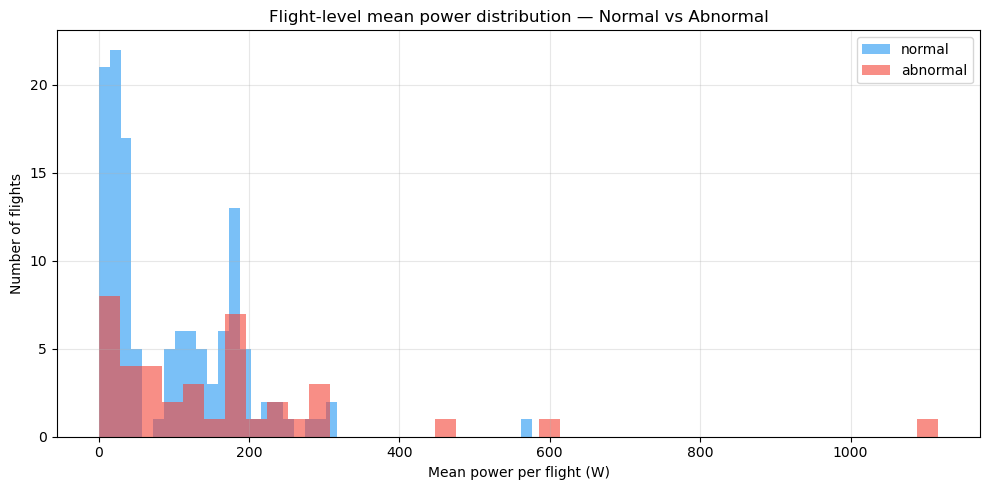

In [244]:
required_cols = ["log_id", "dataset_label", "power_w"]
for col in required_cols:
    if col not in df.columns:
        raise ValueError(f"Missing required column: {col}")

flight_power_summary = (
    df.groupby(["log_id","dataset_label"], as_index=False)
      .agg(mean_power_w=("power_w","mean"))
)

plot_df = flight_power_summary.copy()
plot_df["dataset_label"] = pd.Categorical(
    plot_df["dataset_label"], categories=["normal","abnormal"]
)

fig, ax = plt.subplots(figsize=(10, 5))
for label, color in [("normal","#2196F3"), ("abnormal","#F44336")]:
    vals = plot_df[plot_df["dataset_label"]==label]["mean_power_w"]
    ax.hist(vals, bins=40, alpha=0.6, color=color, label=label, edgecolor="none")
ax.set_xlabel("Mean power per flight (W)")
ax.set_ylabel("Number of flights")
ax.set_title("Flight-level mean power distribution — Normal vs Abnormal")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(EDA_DIR / "flight_power_distribution.png", dpi=150)
plt.show()

In [245]:
print(f"Dataset shape after cleaning: {df.shape}")
print(f"Flights: {df['log_id'].nunique()}")
print(df["dataset_label"].value_counts())

Dataset shape after cleaning: (951265, 380)
Flights: 165
dataset_label
normal      690380
abnormal    260885
Name: count, dtype: int64


## 19. Missing value report

In [246]:
MISSING_THRESHOLD = 80

missing_report = pd.DataFrame({
    "column"          : df.columns,
    "missing_count"   : df.isna().sum().values,
    "missing_percent" : df.isna().mean().values * 100,
    "data_type"       : df.dtypes.astype(str).values,
    "unique_values"   : df.nunique(dropna=True).values
}).sort_values("missing_percent", ascending=False).reset_index(drop=True)

print(f"Columns 100% missing : {(missing_report['missing_percent']==100).sum()}")
print(f"Columns >80% missing : {(missing_report['missing_percent']>MISSING_THRESHOLD).sum()}")
print(f"Columns 0% missing   : {(missing_report['missing_percent']==0).sum()}")
display(missing_report.head(50))
missing_report.to_csv(EDA_DIR / "03_missing_report.csv", index=False)

cols_to_remove_missing = set(
    missing_report[missing_report["missing_percent"] > MISSING_THRESHOLD]["column"].tolist()
)
print("\nColumns removed due to missing >80%:", len(cols_to_remove_missing))

Columns 100% missing : 247
Columns >80% missing : 342
Columns 0% missing   : 23


,column,missing_count,missing_percent,data_type,unique_values
0,vehicle_status__valid_nav_states_mask,951265,100.0,float64,0
1,vehicle_gps_position__altitude_ellipsoid_m,951265,100.0,float64,0
2,vehicle_attitude__delta_q_reset[3],951265,100.0,float64,0
3,vehicle_attitude__delta_q_reset[2],951265,100.0,float64,0
4,vehicle_attitude__delta_q_reset[1],951265,100.0,float64,0
5,vehicle_attitude__delta_q_reset[0],951265,100.0,float64,0
6,vehicle_gps_position__longitude_deg,951265,100.0,float64,0
7,vehicle_gps_position__altitude_msl_m,951265,100.0,float64,0
8,vehicle_gps_position__device_id,951265,100.0,float64,0
9,vehicle_local_position__hagl_min,951265,100.0,float64,0



Columns removed due to missing >80%: 342


## 20. Feature candidate filtering

In [247]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

candidate_features = []
for col in numeric_cols:
    if col in cols_to_exclude or col == target_col:
        continue
    if df[col].isna().mean() * 100 >= MISSING_THRESHOLD:
        continue
    if col in cols_to_remove_missing:
        continue
    if df[col].nunique(dropna=True) <= 1:
        continue
    candidate_features.append(col)

print(f"Candidate features: {len(candidate_features)}")
print(candidate_features)

Candidate features: 20
['battery_status__voltage_v', 'battery_status__voltage_filtered_v', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__cell_count', 'battery_status__warning', 'time_s', 'power_w', 'energy_increment_wh', 'cumulative_energy_wh', 'battery_status__system_source', 'battery_status__voltage_cell_v[0]', 'battery_status__voltage_cell_v[1]', 'battery_status__voltage_cell_v[2]', 'battery_status__voltage_cell_v[3]', 'time_gap', 'post_gap_flag']


## 21. Correlation with target

In [248]:
correlation_rows = []
for col in candidate_features:
    temp = df[[col, target_col]].dropna()
    if len(temp) < 100:
        continue
    pearson  = temp[col].corr(temp[target_col], method="pearson")
    spearman = temp[col].corr(temp[target_col], method="spearman")
    correlation_rows.append({
        "column"            : col,
        "pearson_corr"      : pearson,
        "abs_pearson_corr"  : abs(pearson)  if pd.notna(pearson)  else np.nan,
        "spearman_corr"     : spearman,
        "abs_spearman_corr" : abs(spearman) if pd.notna(spearman) else np.nan
    })

correlation_report = (
    pd.DataFrame(correlation_rows)
    .sort_values("abs_pearson_corr", ascending=False)
    .reset_index(drop=True)
)
display(correlation_report.head(40))
correlation_report.to_csv(EDA_DIR / "04_correlation_with_target.csv", index=False)

,column,pearson_corr,abs_pearson_corr,spearman_corr,abs_spearman_corr
0,energy_increment_wh,0.948318,0.948318,0.908304,0.908304
1,power_w,0.948318,0.948318,0.908304,0.908304
2,battery_status__current_filtered_a,0.722004,0.722004,0.840890,0.840890
3,battery_status__current_a,0.709657,0.709657,0.831327,0.831327
4,cumulative_energy_wh,0.696927,0.696927,0.730138,0.730138
5,battery_status__cell_count,0.652518,0.652518,0.318957,0.318957
6,battery_status__discharged_mah,0.621934,0.621934,0.662440,0.662440
7,battery_status__voltage_filtered_v,0.589290,0.589290,0.088074,0.088074
8,battery_status__voltage_v,0.582599,0.582599,0.112399,0.112399
9,battery_status__scale,0.211372,0.211372,0.184891,0.184891


## 22. Mutual information

In [249]:
MI_SAMPLE = 100_000
mi_sample = df[candidate_features + [target_col]].dropna(subset=[target_col]).copy()
if len(mi_sample) > MI_SAMPLE:
    mi_sample = mi_sample.sample(n=MI_SAMPLE, random_state=42)

X_mi      = SimpleImputer(strategy="median").fit_transform(mi_sample[candidate_features])
y_mi      = mi_sample[target_col]
mi_scores = mutual_info_regression(X_mi, y_mi, random_state=42)

mi_report = (
    pd.DataFrame({"column": candidate_features, "mutual_information_score": mi_scores})
    .sort_values("mutual_information_score", ascending=False)
    .reset_index(drop=True)
)
display(mi_report.head(40))
mi_report.to_csv(EDA_DIR / "05_mutual_information.csv", index=False)

,column,mutual_information_score
0,cumulative_energy_wh,2.206818
1,battery_status__discharged_mah,2.203782
2,battery_status__current_filtered_a,2.139716
3,battery_status__voltage_filtered_v,1.800383
4,energy_increment_wh,1.662770
5,power_w,1.662013
6,battery_status__voltage_v,1.551346
7,battery_status__current_a,1.544510
8,battery_status__remaining,1.127385
9,battery_status__scale,1.066850


## 23. Select final features

In [250]:
#Drop structurally missing and redundant columns
ALWAYS_EXCLUDE = [
    "battery_status__voltage_cell_v[0]",
    "battery_status__voltage_cell_v[1]",
    "battery_status__voltage_cell_v[2]",
    "battery_status__voltage_cell_v[3]",
    "energy_increment_wh",  # duplicate of power_w
]

top_corr_features = correlation_report.head(30)["column"].tolist()
top_mi_features   = mi_report.head(30)["column"].tolist()
valid_core        = [c for c in allowed_core_features if c in candidate_features]

final_feature_cols = sorted(
    set(valid_core + top_corr_features + top_mi_features)
    - set(ALWAYS_EXCLUDE)
)

print(f"Final feature count: {len(final_feature_cols)}")
for i, col in enumerate(final_feature_cols, 1):
    print(f"  {i:2d}. {col}")

Final feature count: 15
   1. battery_status__cell_count
   2. battery_status__current_a
   3. battery_status__current_filtered_a
   4. battery_status__discharged_mah
   5. battery_status__remaining
   6. battery_status__scale
   7. battery_status__system_source
   8. battery_status__voltage_filtered_v
   9. battery_status__voltage_v
  10. battery_status__warning
  11. cumulative_energy_wh
  12. post_gap_flag
  13. power_w
  14. time_gap
  15. time_s


## 24. Review metadata features before removal

In [251]:
review_cols = [
    "battery_status__cell_count",
    "battery_status__scale",
    "battery_status__system_source",
    "battery_status__warning"
]

print("1. Value distribution")
for col in review_cols:
    if col not in df.columns:
        print(f"  {col}: NOT IN DATA")
        continue
    print("\n" + "="*60)
    print(col)
    print("Unique values:", df[col].nunique(dropna=True))
    print(df[col].value_counts(dropna=False).head(10))

print("\n2. Pearson correlation with target")
corr_results = []
for col in review_cols:
    if col not in df.columns:
        continue
    corr = df[col].corr(df[target_col])
    corr_results.append({"feature": col, "pearson_corr": corr})
display(pd.DataFrame(corr_results).sort_values("pearson_corr", ascending=False))

print("\n3. Mutual Information score")
display(mi_report[mi_report["column"].isin(review_cols)]
        .sort_values("mutual_information_score", ascending=False))

1. Value distribution

battery_status__cell_count
Unique values: 5
battery_status__cell_count
3.0     683532
4.0     176295
6.0      58171
12.0     28370
0.0       4897
Name: count, dtype: int64

battery_status__scale
Unique values: 162776
battery_status__scale
1.000000    153514
1.072844     10832
1.072846      2526
1.000157        36
1.027592        30
1.000063        30
1.026662        30
1.026662        30
1.001675        30
1.000568        30
Name: count, dtype: int64

battery_status__system_source
Unique values: 2
battery_status__system_source
1.0    748075
NaN    141782
0.0     61408
Name: count, dtype: int64

battery_status__warning
Unique values: 4
battery_status__warning
0.0    939524
1.0      9236
3.0      2107
2.0       398
Name: count, dtype: int64

2. Pearson correlation with target


,feature,pearson_corr
0,battery_status__cell_count,0.652518
1,battery_status__scale,0.211372
2,battery_status__system_source,0.064587
3,battery_status__warning,0.031827



3. Mutual Information score


,column,mutual_information_score
9,battery_status__scale,1.066850
11,battery_status__cell_count,0.501644
12,battery_status__system_source,0.139959
17,battery_status__warning,0.035657


## 25. Remove weak features

In [252]:
cols_to_remove = [
    "battery_status__system_source",
    "battery_status__warning"
]

final_feature_cols = [c for c in final_feature_cols if c not in cols_to_remove]

print("Removed:", cols_to_remove)
print("Updated final feature count:", len(final_feature_cols))
display(pd.DataFrame({
    "No.": range(1, len(final_feature_cols)+1),
    "Final Feature": final_feature_cols
}))

Removed: ['battery_status__system_source', 'battery_status__warning']
Updated final feature count: 13


,No.,Final Feature
0,1,battery_status__cell_count
1,2,battery_status__current_a
2,3,battery_status__current_filtered_a
3,4,battery_status__discharged_mah
4,5,battery_status__remaining
5,6,battery_status__scale
6,7,battery_status__voltage_filtered_v
7,8,battery_status__voltage_v
8,9,cumulative_energy_wh
9,10,post_gap_flag


## 26. idle phase flag

In [253]:
df["is_idle"] = (df["power_w"] < 10).astype(np.float32)

## 27. 3-second rolling std of power

In [254]:
df["power_w_rolling_std_3s"] = (
    df.groupby("log_id")["power_w"]
    .transform(lambda x: x.rolling(30, min_periods=1).std().fillna(0))
)

for feat in ["is_idle", "power_w_rolling_std_3s"]:
    if feat not in final_feature_cols:
        final_feature_cols.append(feat)

## 28. Correlation matrix

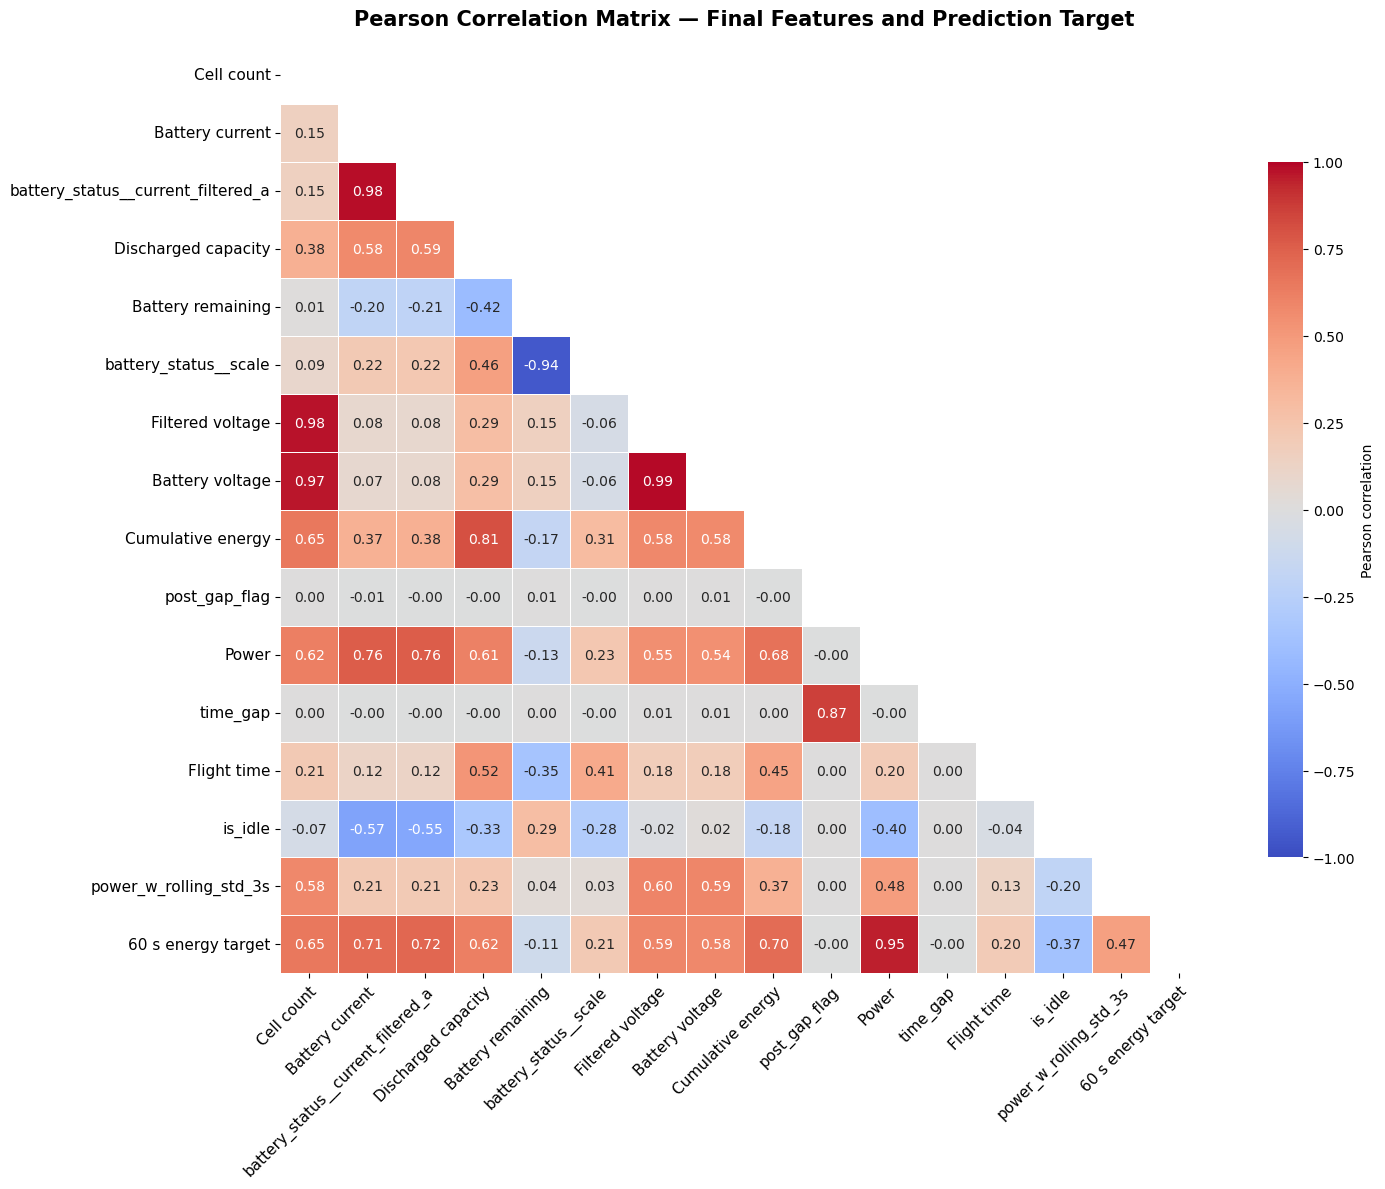


Top correlations with target:
power_w                               0.948318
battery_status__current_filtered_a    0.722004
battery_status__current_a             0.709657
cumulative_energy_wh                  0.696927
battery_status__cell_count            0.652518
battery_status__discharged_mah        0.621934
battery_status__voltage_filtered_v    0.589290
battery_status__voltage_v             0.582599
power_w_rolling_std_3s                0.466326
is_idle                               0.373377
battery_status__scale                 0.211372
time_s                                0.202616
battery_status__remaining             0.106365
post_gap_flag                         0.002142
time_gap                              0.001347
Name: target_energy_next_60s_wh, dtype: float64


In [255]:
corr_cols = final_feature_cols + [target_col]


label_map = {
    "battery_status__voltage_v": "Battery voltage",
    "battery_status__current_a": "Battery current",
    "battery_status__remaining": "Battery remaining",
    "battery_status__discharged_mah": "Discharged capacity",
    "battery_status__cell_count": "Cell count",
    "battery_status__voltage_cell_v": "Cell voltage",
    "battery_status__voltage_filtered_v": "Filtered voltage",
    "cumulative_energy_wh": "Cumulative energy",
    "power_w": "Power",
    "time_s": "Flight time",
    "target_energy_next_60s_wh": "60 s energy target"
}

corr_matrix = df[corr_cols].corr()

# Rename only for visualisation
corr_display = corr_matrix.rename(
    index=label_map,
    columns=label_map
)

mask = np.triu(
    np.ones_like(corr_display, dtype=bool)
)

fig, ax = plt.subplots(figsize=(15, 12))

sns.heatmap(
    corr_display,
    ax=ax,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "shrink": 0.75,
        "label": "Pearson correlation"
    },
    annot_kws={"size": 10}
)

ax.set_title(
    "Pearson Correlation Matrix — Final Features and Prediction Target",
    fontsize=15,
    fontweight="bold",
    pad=15
)

annot_kws={"size": 11}

ax.tick_params(
    axis="x",
    labelrotation=45,
    labelsize=11
)

ax.tick_params(
    axis="y",
    labelrotation=0,
    labelsize=11
)

# Align rotated x labels neatly
plt.setp(
    ax.get_xticklabels(),
    ha="right",
    rotation_mode="anchor"
)

plt.tight_layout()

plt.savefig(
    EDA_DIR / "correlation_matrix_final_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nTop correlations with target:")
print(
    corr_matrix[target_col]
    .drop(target_col)
    .abs()
    .sort_values(ascending=False)
)

## 29. Outlier flight removal (Remove 12-cell flights)

Two flights with 12-cell batteries identified — physically different aircraft class. All other flights use 3, 4, or 6 cells. Removal justified on hardware heterogeneity grounds.

In [256]:
flights_before = df["log_id"].nunique()

twelve_cell_ids = (
    df.groupby("log_id")["battery_status__cell_count"]
    .median()
    .loc[lambda x: x >= 12]
    .index
)

print(f"12-cell flights found: {len(twelve_cell_ids)}")
for fid in twelve_cell_ids:
    label  = df.loc[df["log_id"]==fid, "dataset_label"].iloc[0]
    power  = df.loc[df["log_id"]==fid, "power_w"].mean()
    cells  = df.loc[df["log_id"]==fid, "battery_status__cell_count"].median()
    print(f"  {fid[:8]}  label={label}  cells={cells}  mean_power={power:.1f}W")

df = df[~df["log_id"].isin(twelve_cell_ids)].reset_index(drop=True)

print(f"\nFlights before : {flights_before}")
print(f"Flights after  : {df['log_id'].nunique()}")
print(f"Reason         : 12-cell battery — incompatible aircraft class")

12-cell flights found: 2
  3d552044  label=abnormal  cells=12.0  mean_power=1116.4W
  75678c0f  label=abnormal  cells=12.0  mean_power=302.7W

Flights before : 165
Flights after  : 163
Reason         : 12-cell battery — incompatible aircraft class


## 30. Save

In [257]:
final_cols = ["log_id", "dataset_label"] + final_feature_cols + [target_col]

missing_cols = [c for c in final_cols if c not in df.columns]
if missing_cols:
    print(f"WARNING — missing columns: {missing_cols}")
else:
    print("All columns present")

clean_to_save = df[final_cols].copy()

CLEAN_PATH = PROJECT_DIR / "processed_10hz" / "v2" / "clean_dataset_final.csv"
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
clean_to_save.to_csv(CLEAN_PATH, index=False)

print(f"\nSaved: {CLEAN_PATH}")
print(f"Shape: {clean_to_save.shape}")
print(f"Columns: {clean_to_save.columns.tolist()}")
print(f"Flights: {clean_to_save['log_id'].nunique()}")
print(f"is_idle in features        : {'is_idle' in final_feature_cols}")
print(f"power_w_rolling_std_3s     : {'power_w_rolling_std_3s' in final_feature_cols}")

All columns present

Saved: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/v2/clean_dataset_final.csv
Shape: (922895, 18)
Columns: ['log_id', 'dataset_label', 'battery_status__cell_count', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__voltage_filtered_v', 'battery_status__voltage_v', 'cumulative_energy_wh', 'post_gap_flag', 'power_w', 'time_gap', 'time_s', 'is_idle', 'power_w_rolling_std_3s', 'target_energy_next_60s_wh']
Flights: 163
is_idle in features        : True
power_w_rolling_std_3s     : True
